# 30 基于 LSTM 与 Prophet 的时间序列预测与对比

> **模块**：时间序列 ｜ **数据**：`flight.csv`、`AirPassengers.csv` ｜ **依赖**：numpy、pandas、matplotlib、scikit-learn、statsmodels 等

**什么是时间序列分析？**

时间序列分析包括分析时间序列数据的方法，以提取有意义的统计数据和数据的其他特征。时间序列预测是使用模型根据先前观察到的值预测未来值。虽然回归分析通常用于测试一个或多个不同时间序列之间的关系，但这种分析通常不被称为“时间序列分析”，它特别指的是单个序列中不同时间点之间的关系。中断时间序列分析用于检测干预前后时间序列演变的变化，这些变化可能会影响潜在变量。

参考：https://en.wikipedia.org/wiki/Time_series

Prophet 是 Facebook 开源的 Python 预测库，该模型不仅能使用额外的信息还能融入节假日信息等，NeuralProphet 是升级版的 Prophet，两点显著的变化：一是增加了AR网络，二是Pytorch作为backend (Pytorch代替Stan)

`prophet:https://github.com/facebook/prophet`
`NeuralProphet:https://neuralprophet.com/`

要求：使用Prophet模型构建多元时间序列模型，使用rainfall，temperature，drainage_volume，river_hydrometry四个变量来对 $ y $ 进行预测

模型如下：$ \quad y=f $（rainfall，temperature，drainage_volume，river_hydrometry）
其中，$ f $ 即为Prophet模型

$$
y(t)=g(t)+s(t)+h(t)+/epsilon_{t}

$$
- $ g(t) $ 表示趋势项，它表示时间序列在非周期上面的变化趋势；
- $ s(t) $ 表示周期项，或者称为季节项，一般来说是以周或者年为单位；
- $ h(t) $ 表示节假日项，表示时间序列中那些潜在的具有非固定周期的节假日对预测值造成的影响；
- $ /epsilon_{t} $ 即误差项或者称为剩余项，表示模型未预测到的波动，$ /epsilon_{t} $ 服从高斯分布；

Prophet 算法就是通过拟合这几项，然后最后把它们累加起来就得到了时间序列的预测值。
其中 $ g(t) $ 通过逻辑回归函数（非线性增长）和分段线性函数（线性增长）来拟合
$ s(t) $ 通过傅里叶级数来拟合

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import torch

def plot_decompose(decompose_result):
    fig, (ax1,ax2,ax3,ax4) = plt.subplots(4,1,figsize=(12,20))
    decompose_result.observed.plot(legend=False,ax=ax1,fontsize = 20,grid=True,linewidth = 3)
    ax1.set_ylabel("Observed",fontsize = 20)
    decompose_result.trend.plot(legend=False,ax=ax2,fontsize = 20,grid=True,linewidth = 3)
    ax2.set_ylabel("Trend",fontsize = 20)
    decompose_result.seasonal.plot(legend=False,ax=ax3,fontsize = 20,grid=True,linewidth = 3)
    ax3.set_ylabel("Seasonal",fontsize = 20)
    decompose_result.resid.plot(legend=False,ax=ax4,fontsize = 20,grid=True,linewidth = 3)
    ax4.set_ylabel("Residual",fontsize = 20)

flight_data = pd.read_csv('../data/flight.csv')
cm = sns.light_palette("green", as_cmap=True)
flight_data.head(20).style.background_gradient(cmap=cm)

,year,month,passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121
5,1949,June,135
6,1949,July,148
7,1949,August,148
8,1949,September,136
9,1949,October,119


In [2]:
print(flight_data.describe())
print('-'*40)
print(flight_data.tail())
print(flight_data.shape)
print(flight_data.info())

              year  passengers
count   144.000000  144.000000
mean   1954.500000  280.298611
std       3.464102  119.966317
min    1949.000000  104.000000
25%    1951.750000  180.000000
50%    1954.500000  265.500000
75%    1957.250000  360.500000
max    1960.000000  622.000000
----------------------------------------
     year      month  passengers
139  1960     August         606
140  1960  September         508
141  1960    October         461
142  1960   November         390
143  1960   December         432
(144, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        144 non-null    int64 
 1   month       144 non-null    object
 2   passengers  144 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 3.5+ KB
None


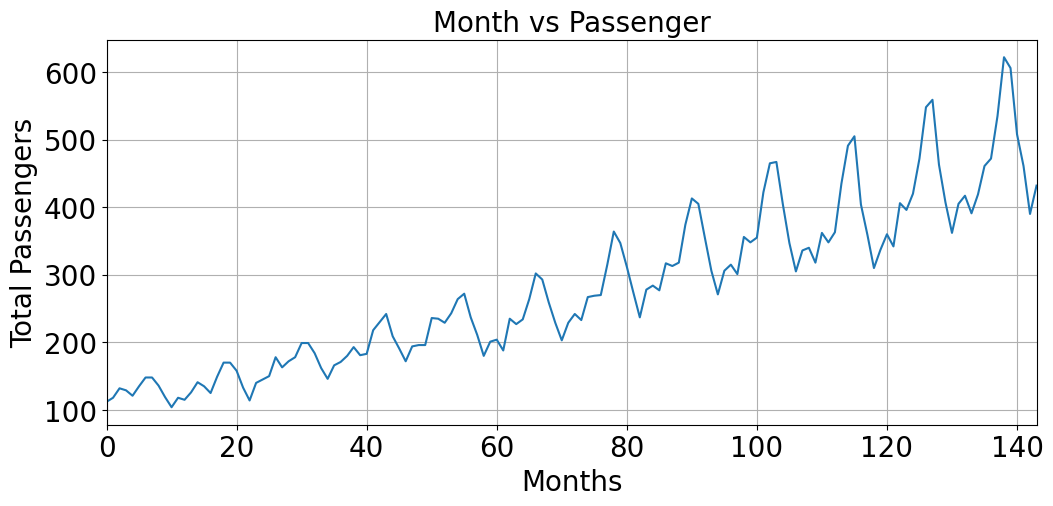

In [3]:
plt.figure(figsize=(12,5))
plt.title('Month vs Passenger',fontsize = 20)
plt.ylabel('Total Passengers',fontsize = 20)
plt.xlabel('Months',fontsize = 20)
plt.grid(True)
plt.autoscale(axis='x',tight=True)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot(flight_data['passengers'])

In [4]:
flight_data['passengers']

0      112
1      118
2      132
3      129
4      121
      ... 
139    606
140    508
141    461
142    390
143    432
Name: passengers, Length: 144, dtype: int64

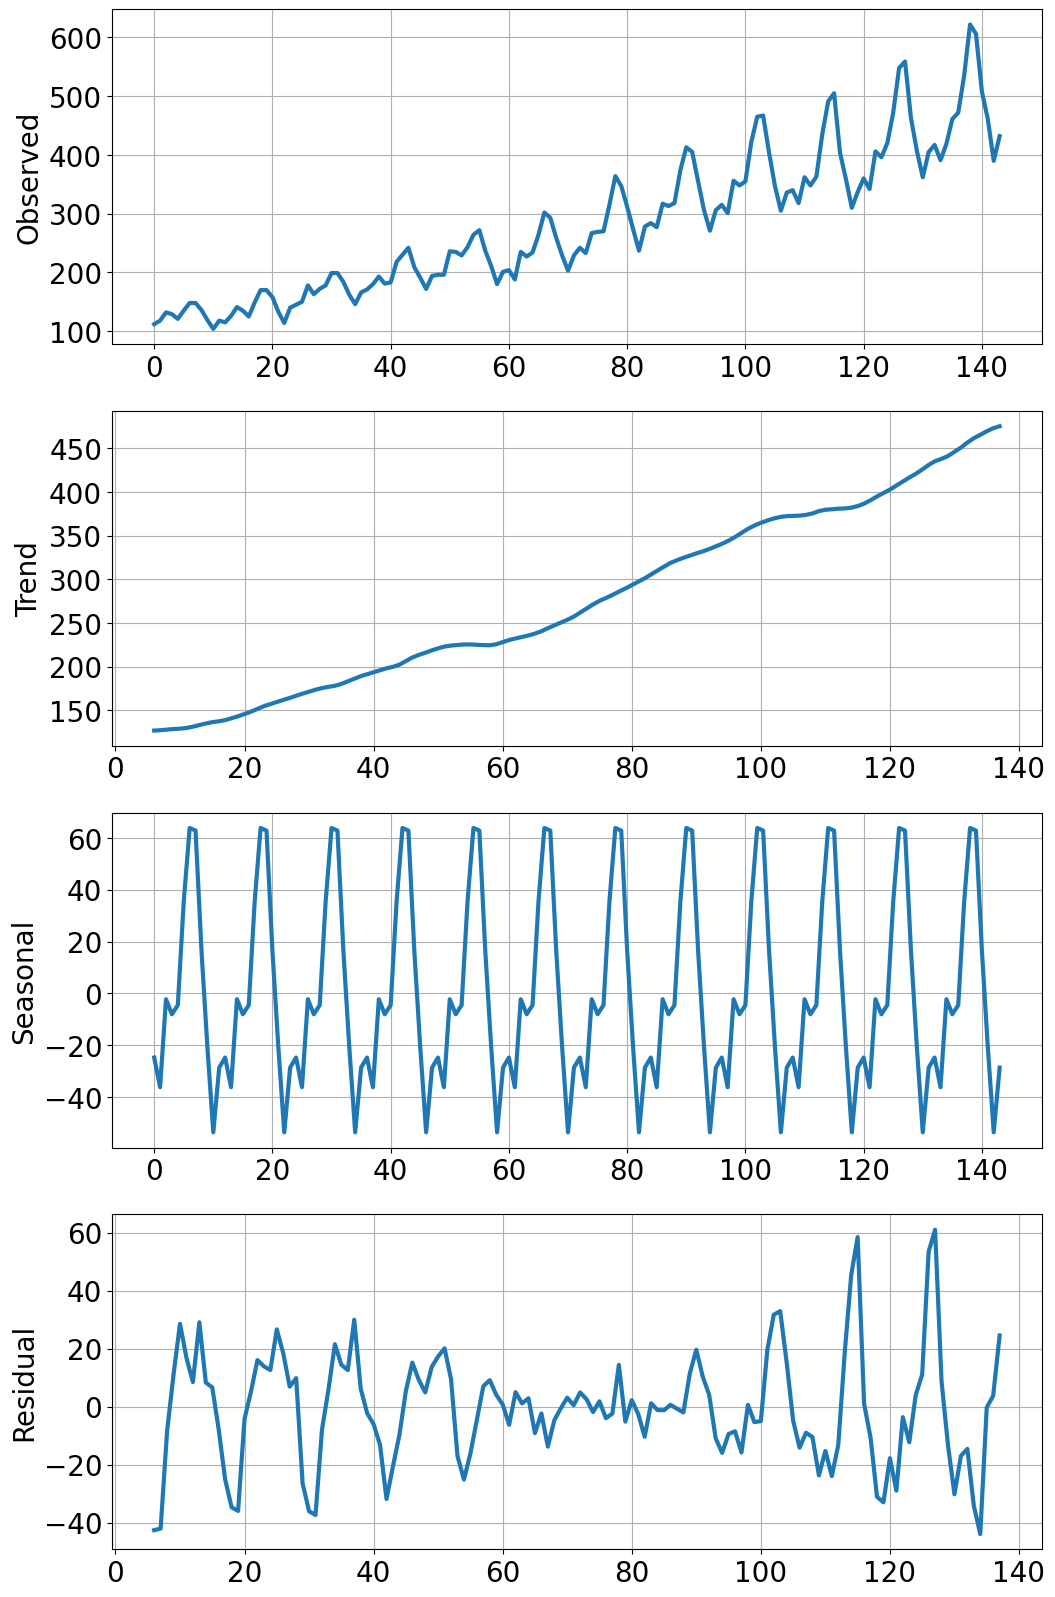

In [5]:
import statsmodels
import statsmodels.api as sm  
from statsmodels.tsa.stattools import acf  
from statsmodels.tsa.stattools import pacf
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(flight_data['passengers'], period=12) 
plot_decompose(decomposition)

In [6]:
all_data = flight_data['passengers'].values.astype(float)
print(all_data)

[112. 118. 132. 129. 121. 135. 148. 148. 136. 119. 104. 118. 115. 126.
 141. 135. 125. 149. 170. 170. 158. 133. 114. 140. 145. 150. 178. 163.
 172. 178. 199. 199. 184. 162. 146. 166. 171. 180. 193. 181. 183. 218.
 230. 242. 209. 191. 172. 194. 196. 196. 236. 235. 229. 243. 264. 272.
 237. 211. 180. 201. 204. 188. 235. 227. 234. 264. 302. 293. 259. 229.
 203. 229. 242. 233. 267. 269. 270. 315. 364. 347. 312. 274. 237. 278.
 284. 277. 317. 313. 318. 374. 413. 405. 355. 306. 271. 306. 315. 301.
 356. 348. 355. 422. 465. 467. 404. 347. 305. 336. 340. 318. 362. 348.
 363. 435. 491. 505. 404. 359. 310. 337. 360. 342. 406. 396. 420. 472.
 548. 559. 463. 407. 362. 405. 417. 391. 419. 461. 472. 535. 622. 606.
 508. 461. 390. 432.]


In [7]:
test_data_size = 12

train_data = all_data[:-test_data_size]
test_data = all_data[-test_data_size:]
print(len(train_data))
print(len(test_data))

132
12


In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-1, 1))
train_data_normalized = scaler.fit_transform(train_data .reshape(-1, 1))

#train_data_normalized = torch.FloatTensor(train_data_normalized).view(-1)

In [9]:
train_window = 12

def create_inout_sequences(input_data, window):
    inout_seq = []
    L = len(input_data)
    for i in range(L-window):
        train_seq = input_data[i:i+window]
        train_label = input_data[i+window:i+window+1]
        inout_seq.append((train_seq ,train_label))
    return inout_seq

train_inout_seq = create_inout_sequences(train_data_normalized, train_window)
train_inout_seq[:5]

[(array([[-0.96483516],
         [-0.93846154],
         [-0.87692308],
         [-0.89010989],
         [-0.92527473],
         [-0.86373626],
         [-0.80659341],
         [-0.80659341],
         [-0.85934066],
         [-0.93406593],
         [-1.        ],
         [-0.93846154]]),
  array([[-0.95164835]])),
 (array([[-0.93846154],
         [-0.87692308],
         [-0.89010989],
         [-0.92527473],
         [-0.86373626],
         [-0.80659341],
         [-0.80659341],
         [-0.85934066],
         [-0.93406593],
         [-1.        ],
         [-0.93846154],
         [-0.95164835]]),
  array([[-0.9032967]])),
 (array([[-0.87692308],
         [-0.89010989],
         [-0.92527473],
         [-0.86373626],
         [-0.80659341],
         [-0.80659341],
         [-0.85934066],
         [-0.93406593],
         [-1.        ],
         [-0.93846154],
         [-0.95164835],
         [-0.9032967 ]]),
  array([[-0.83736264]])),
 (array([[-0.89010989],
         [-0.92527473],
  

## 1. LSTM 模型

### 1.1 什么是 LSTM？

**长短期记忆（LSTM）**是一种用于深度学习领域的人工循环神经网络（RNN）架构。与标准前馈神经网络不同，LSTM 具有反馈连接。它不仅可以处理单个数据点（如图像），还可以处理整个数据序列（如语音或视频）。

例如，LSTM 适用于以下任务：
- 网络流量分析
- IDS（入侵检测系统）中的异常检测
- 非分段、连续手写识别
- 语音识别
- 时间序列预测

### 1.2 LSTM 单元结构

一个普通的 LSTM 单元由以下组件组成：
- **单元（Cell）**：记住任意时间间隔内的值
- **输入门（Input Gate）**：调节信息流入单元
- **输出门（Output Gate）**：调节信息流出单元
- **遗忘门（Forget Gate）**：决定哪些信息需要丢弃

这三个门共同调节信息的流入和流出，使 LSTM 能够学习长期依赖关系。

### 1.3 LSTM 的优势

LSTM 网络非常适合基于时间序列数据进行分类、处理和预测，原因如下：

1. **处理未知滞后**：时间序列中的重要事件之间可能存在未知持续时间的滞后
2. **解决梯度消失问题**：LSTM 的开发是为了处理训练传统 RNN 时可能遇到的梯度消失问题
3. **对间隙长度不敏感**：这是 LSTM 在众多应用中优于 RNN、隐马尔可夫模型和其他序列学习方法的关键优势

*参考文献: https://en.wikipedia.org/wiki/Long_short-term_memory*

### 1.4 模型参数说明

本示例使用简单的 LSTM 层进行建模，主要参数包括：

- **input_size**：对应输入特征数。序列长度为 12（12 个月），但每月只有 1 个值（乘客总数），因此输入大小为 **1**
- **hidden_layer_size**：指定隐藏层的神经元数量，控制模型的复杂度
- **output_size**：输出大小为 **1**，因为每次预测下一个月的乘客数量

In [10]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

class LSTM(nn.Module):
    def __init__(self, input_size=1, hidden_layer_size=128, num_layers=2, output_size=1):
        super().__init__()
        self.hidden_layer_size = hidden_layer_size
        # 添加 batch_first=True
        self.lstm = nn.LSTM(input_size, hidden_layer_size, num_layers=num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_layer_size, output_size)

    def forward(self, input_seq):
        # 使用 reshape 替代 view
        lstm_out, _ = self.lstm(input_seq.reshape(1, len(input_seq), -1))
        predictions = self.linear(lstm_out[:,-1,:])
        return predictions[-1]

In [11]:
model = LSTM()
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
print(model)

LSTM(
  (lstm): LSTM(1, 128, num_layers=2, batch_first=True)
  (linear): Linear(in_features=128, out_features=1, bias=True)
)


In [12]:
epochs = 10 # 500

for i in range(epochs):
    for seq, labels in train_inout_seq:
        optimizer.zero_grad()
        
        # 修复：将 numpy 数组转换为张量
        seq_tensor = torch.FloatTensor(seq)
        labels_tensor = torch.FloatTensor(labels)
        
        y_pred = model(seq_tensor)
        single_loss = loss_function(y_pred, labels_tensor)
        single_loss.backward()
        optimizer.step()

    if i % 25 == 1:
        print(f'epoch: {i:3} loss: {single_loss.item():10.8f}')
print(f'epoch: {i:3} loss: {single_loss.item():10.8f}')

c:\Users\yohoten\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\nn\modules\loss.py:616: UserWarning: Using a target size (torch.Size([1, 1])) that is different to the input size (torch.Size([1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


epoch:   1 loss: 0.00204242
epoch:   9 loss: 0.24294978


测试集包含过去12个月的乘客数据。该模型被训练为使用序列长度12进行预测。让我们预测过去12个月的数据。

In [13]:
fut_pred = 12

# 修复：将嵌套列表转换为一维列表
test_inputs = train_data_normalized[-train_window:].flatten().tolist()
print(test_inputs)

model.eval()

for i in range(fut_pred):
    # 修复：一维列表可以直接转换为张量并 reshape
    seq = torch.FloatTensor(test_inputs[-train_window:]).view(-1, 1)
    with torch.no_grad():
        test_inputs.append(model(seq).item())

[0.12527472527472527, 0.04615384615384621, 0.32747252747252764, 0.2835164835164836, 0.3890109890109892, 0.6175824175824178, 0.9516483516483516, 1.0000000000000002, 0.578021978021978, 0.331868131868132, 0.13406593406593403, 0.32307692307692304]


In [14]:
test_inputs[fut_pred:]

[-0.1655285358428955,
 -0.165535107254982,
 -0.16553178429603577,
 -0.16552871465682983,
 -0.1655196100473404,
 -0.16550792753696442,
 -0.16550950706005096,
 -0.16552327573299408,
 -0.16553224623203278,
 -0.16553492844104767,
 -0.16553613543510437,
 -0.16553664207458496]

由于我们对数据集进行了归一化训练，因此预测值也进行了归一化。我们需要将归一化的预测值转换为实际的预测值。使用您用于规范化数据集的min/max缩放器对象的inverse_transform将其转换为原始值。

In [15]:
actual_predictions = scaler.inverse_transform(np.array(test_inputs[train_window:] ).reshape(-1, 1))
print(actual_predictions)

[[293.8422581 ]
 [293.8407631 ]
 [293.84151907]
 [293.84221742]
 [293.84428871]
 [293.84694649]
 [293.84658714]
 [293.84345477]
 [293.84141398]
 [293.84080378]
 [293.84052919]
 [293.84041393]]


In [16]:
x = np.arange(132, 144, 1)
print(x)

[132 133 134 135 136 137 138 139 140 141 142 143]


LSTM的预测由橙色线表示。虽然结果并不准确，但根据过去12个月旅行乘客总数的波动，可以发现上升趋势。通过在LSTM层中使用更多的epoch和更多的神经元，可以实现更好的性能。

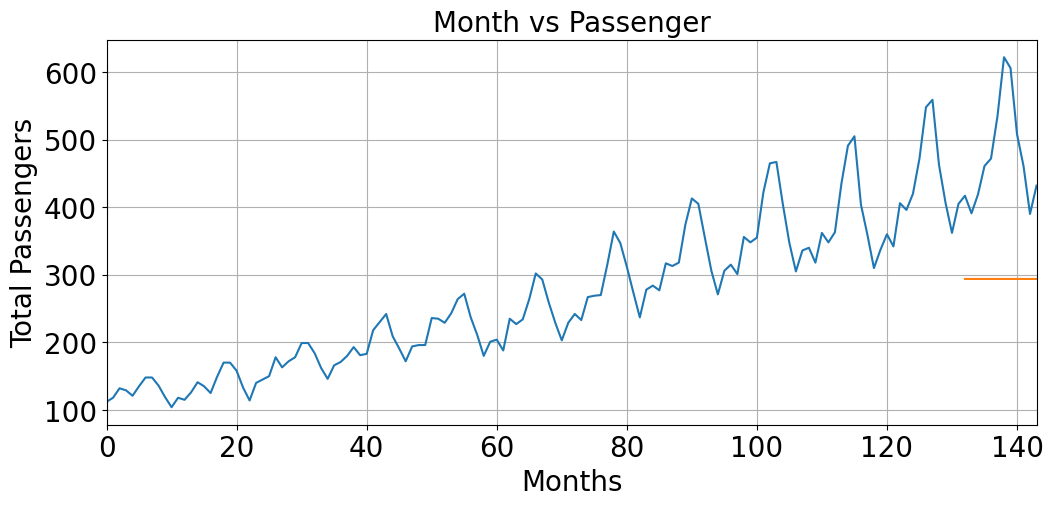

In [17]:
plt.figure(figsize=(12,5))
plt.title('Month vs Passenger',fontsize = 20)
plt.ylabel('Total Passengers',fontsize = 20)
plt.xlabel('Months',fontsize = 20)
plt.grid(True)
plt.autoscale(axis='x',tight=True)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot(flight_data['passengers'])
plt.plot(x,actual_predictions)

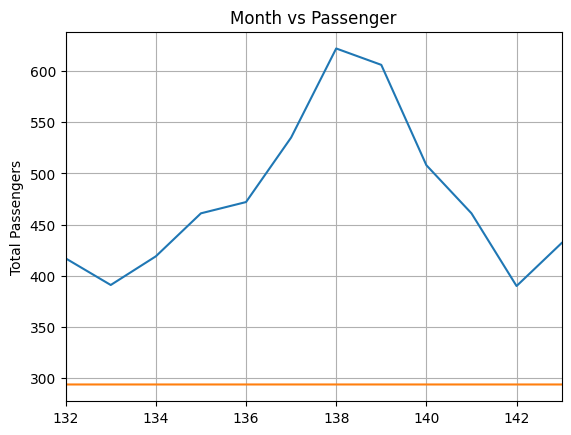

In [18]:
plt.title('Month vs Passenger')
plt.ylabel('Total Passengers')
plt.grid(True)
plt.autoscale(axis='x', tight=True)

plt.plot(flight_data['passengers'][-train_window:])
plt.plot(x,actual_predictions)
plt.show()

进行时间序列分析检查是否在保持原始时间序列的趋势、季节性和残差的同时学习了预测结果。

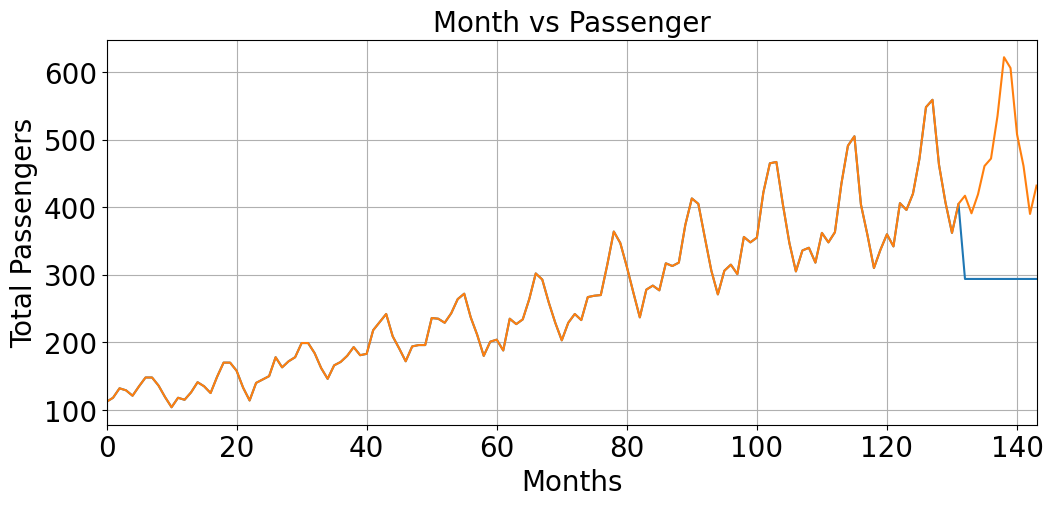

In [19]:
flight_data['passengers'][:-train_window]
train_df = pd.DataFrame(flight_data['passengers'][:-train_window])
actual_df = pd.DataFrame(actual_predictions)
actual_df.columns = ['passengers']
new_predict = pd.concat([train_df,actual_df]).reset_index(drop=True)

plt.figure(figsize=(12,5))
plt.title('Month vs Passenger',fontsize = 20)
plt.ylabel('Total Passengers',fontsize = 20)
plt.xlabel('Months',fontsize = 20)
plt.grid(True)
plt.autoscale(axis='x',tight=True)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot(new_predict)
plt.plot(flight_data['passengers'])

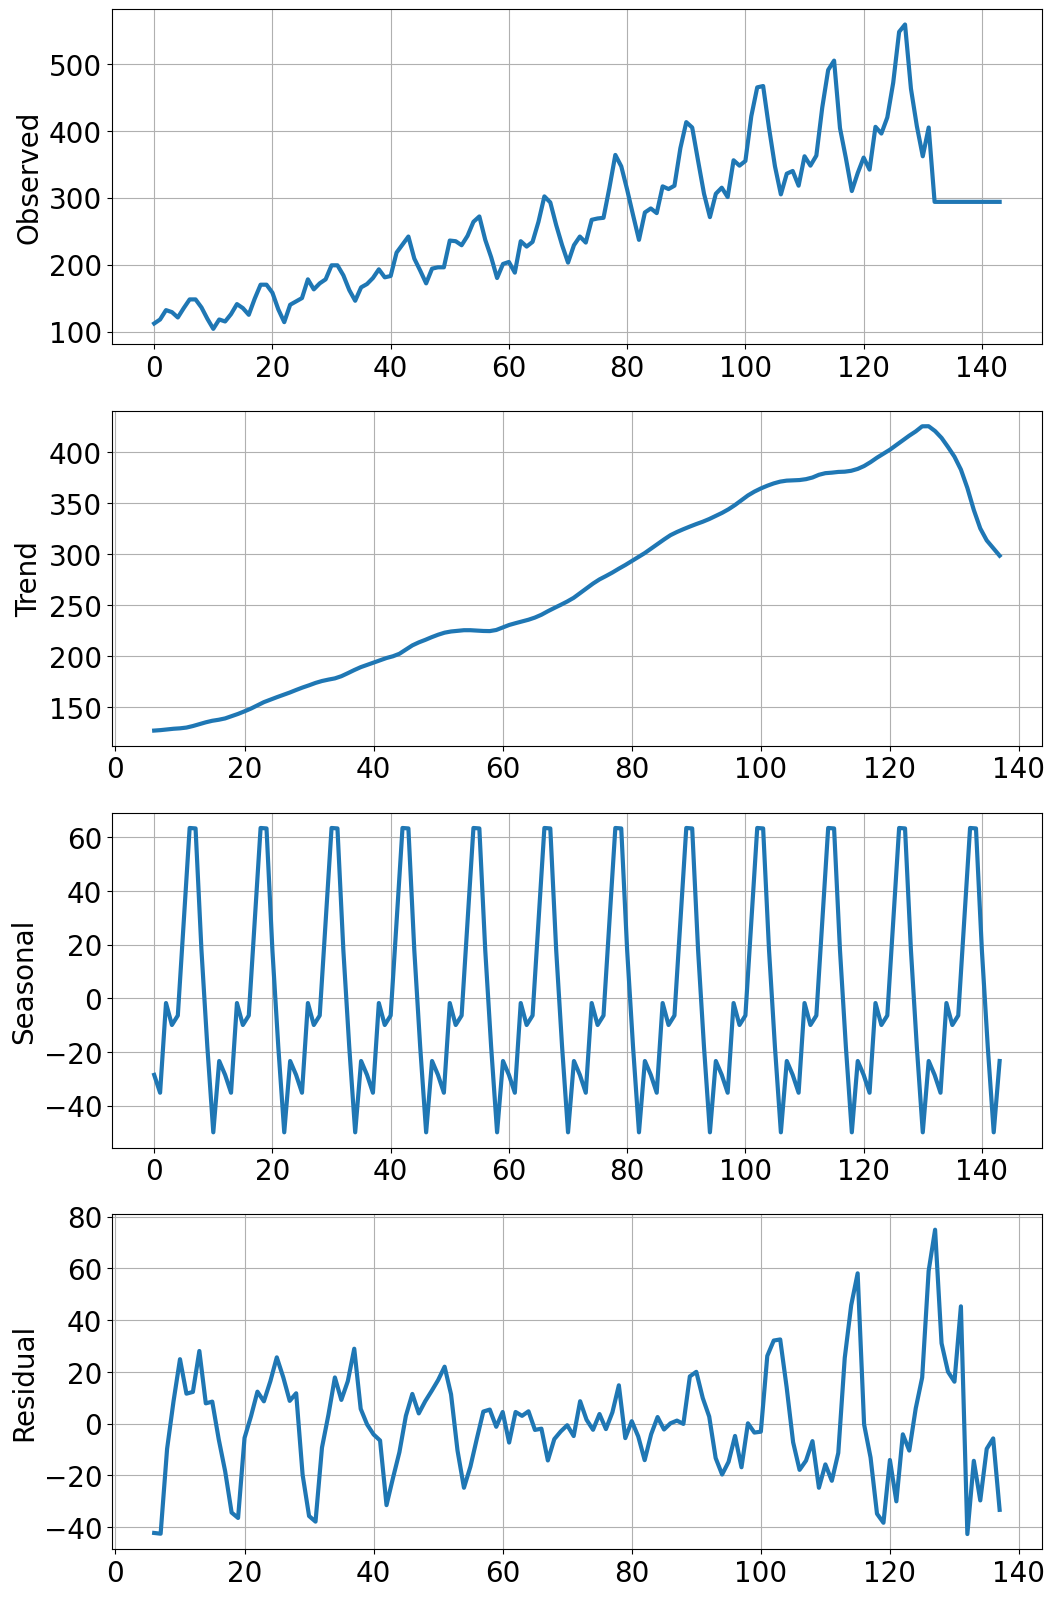

In [20]:
decomposition = seasonal_decompose(new_predict, period=12) 
plot_decompose(decomposition)

从上图可以看出，尽管模型简单，但它在预测时很好地保留了趋势、季节性和残差。


## 2. Prophet 模型


In [ ]:
import os
import pandas as pd
import numpy as np
#import neuralprophet
from prophet import Prophet

In [ ]:
data = pd.read_csv('../data/AirPassengers.csv')
data.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [ ]:
df = flight_data.copy()
month2int = {
    'January': 1,
    'February': 2,
    'March': 3,
    'April': 4,
    'May': 5,
    'June': 6,
    'July': 7,
    'August': 8,
    'September': 9,
    'October': 10,
    'November': 11,
    'December': 12
}
df['month'] = df['month'].map(month2int)
df['day'] = 1
df['ds'] = pd.to_datetime(df[['year','month','day']])
df_new = df.drop(columns=['year','month','day'])
df_new.rename(columns={"passengers": "y"},inplace=True)
df_new.head()

,y,ds
0,112,1949-01-01
1,118,1949-02-01
2,132,1949-03-01
3,129,1949-04-01
4,121,1949-05-01


## 3. NeuralProphet 模型

NeuralProphet是一个基于神经网络的PyTorch实现，为从业者提供了一个用户友好的时间序列预测工具。这在很大程度上受到了Facebook开发的流行预测工具Prophet的启发。NeuralProphet采用完全模块化的架构开发，使其可扩展，以便在未来添加任何其他组件。我们的愿景是为用户开发一个易于使用的预测工具，同时保留Prophet的原始目标，如可解释性、可配置性，并通过使用PyTorch作为后端提供更多功能，如自动差分功能。

In [ ]:
# NeuralProphet 代码（Windows 兼容）
import torch
from neuralprophet.configure import ConfigSeasonality, Season
torch.serialization.add_safe_globals([ConfigSeasonality, Season])

from neuralprophet import NeuralProphet

m = NeuralProphet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

# 训练模型
metrics = m.fit(df_new, freq="MS")

# 预测
forecast = m.predict(df_new)

# 可视化
fig_forecast = m.plot(forecast)
fig_components = m.plot_components(forecast)
fig_model = m.plot_parameters()

# 未来预测
future = m.make_future_dataframe(df_new, periods=12, n_historic_predictions=len(df_new))
forecast_future = m.predict(future)
fig_future = m.plot(forecast_future)

---


## 4. 结果对比

使用简单的 RNN、Prophet 和 NeuralProphet 预测了相同的数据集。所有这些方法似乎都是可预测的。然而，预计在没有恒定趋势和季节性的数据集中，预测能力将下降。换句话说，似乎应该根据相应数据集的领域知识来选择合适的方法。
